In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import random
import pandas as pd

### Generate and Prepare Data

In [ ]:
class_labels = np.array(['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'])
probs = np.loadtxt('irreducible/data/fmh_probs.csv', delimiter = ',')
raw_data = pd.read_csv('irreducible/data/fmh_raw.csv')
counts = 

# Tops vs others
tops= ['Shirt', 'Dress', 'Coat', 'Pullover', 'T-shirt/top']
positive_class = np.logical_or.reduce(([class_labels == tops[i] for i in range(len(tops))]))

# Randomly select 5 classes for attrs with fixed seed (10)
attr_1 = random.Random(10).sample(list(class_labels), 5)
attr_0 = [c for c in class_labels if c not in attr_1]

positive_idx = list(np.where(positive_class)[0])
positive = np.sum(probs[:, positive_idx], axis=1)
negative = 1 - positive
pn = np.vstack((positive, negative))

In [8]:
raw_data

,Input.image_url,Answer.category,PseudoWorkerId
0,4000.jpg,T-shirt/top,0
1,2000.jpg,Bag,1
2,2000.jpg,Bag,0
3,2000.jpg,Bag,2
4,4010.jpg,Sneaker,0
...,...,...,...
667015,1999.jpg,T-shirt/top,415
667016,1999.jpg,T-shirt/top,808
667017,1999.jpg,T-shirt/top,619
667018,1999.jpg,T-shirt/top,612


In [ ]:
# def unpickle(file):
#     with open(file, 'rb') as fo:
#         dict = pickle.load(fo, encoding='bytes')
#     return dict

# soft_label_matrix = np.load('../cifar_experiments/cifar-10h/data/cifar10h-probs.npy')

# dataset = unpickle('../cifar_experiments/cifar-10-batches-py/test_batch')

# # read class mapping from meta file
# meta = unpickle('../cifar_experiments/cifar-10-batches-py/batches.meta')
# class_mapping = {i: label.decode('utf-8') for i, label in enumerate(meta[b'label_names'])}

# # Best combination for high EO
# # class_setup = 'firstfive'
# # attr_setup = 'animals'
# # metric = 'EOP'

# # Best combination for high DP
# class_setup = 'land'
# attr_setup = 'animals'
# metric= 'DP'

# if class_setup == 'firstfive':
#     '''the first five classes are positive and the last five classes are negative'''
#     positive_idx = [0,1,2,3,4]
#     class_1 = [class_mapping[i] for i in positive_idx]
#     class_0 = [class_mapping[i] for i in range(10) if i not in positive_idx]
# elif class_setup == 'odd':
#     '''the odd classes are positive and the even classes are negative'''
#     positive_idx = [0,2,4,6,8]
#     class_1 = [class_mapping[i] for i in positive_idx]
#     class_0 = [class_mapping[i] for i in range(10) if i not in positive_idx]
# elif class_setup == 'land':
#     '''the land-related classes are positive and the rest (e.g., water-related, sky-related) are negative'''
#     class_1 = ['automobile', 'cat', 'deer', 'dog', 'horse', 'truck']
#     class_0 = ['airplane', 'ship', 'frog', 'bird']
# elif class_setup == 'animals':
#     '''animals are positive and the rest (e.g., vehicles) are negative'''
#     class_1 = ['bird', 'cat', 'deer', 'dog', 'frog', 'horse']
#     class_0 = ['airplane', 'automobile', 'ship', 'truck']

# if attr_setup == 'firstfive':
#     '''the first five classes are in attr_0 and the last five classes are in attr_1'''
#     attr_0 = [class_mapping[i] for i in range(5)]
#     attr_1 = [class_mapping[i] for i in range(5,10)]
# elif attr_setup == 'odd':
#     '''the odd classes are in attr_0 and the even classes are in attr_1'''
#     attr_0 = [class_mapping[i] for i in range(10) if i%2==1]
#     attr_1 = [class_mapping[i] for i in range(10) if i%2==0]
# elif attr_setup == 'land':
#     '''the land-related classes are in attr_0 and the rest (e.g., water-related, sky-related) are in attr_1'''
#     attr_0 = ['automobile', 'cat', 'deer', 'dog', 'horse', 'truck']
#     attr_1 = ['airplane', 'ship', 'frog', 'bird']
# elif attr_setup == 'animals':
#     '''animals are in attr_0 and the rest (e.g., vehicles) are in attr_1'''
#     attr_1 = ['bird', 'cat', 'deer', 'dog', 'frog', 'horse']
#     attr_0 = ['airplane', 'automobile', 'ship', 'truck']

# # attr_0 = ['cat', 'dog', 'frog', 'horse', 'deer']
# # attr_1 = ['airplane', 'automobile', 'ship', 'truck', 'bird']

# # # # Objects on land vs others
# # class_0 = ['automobile', 'truck', 'cat', 'deer', 'dog', 'horse']
# # class_1 = ['airplane', 'ship', 'frog', 'bird']

# # Terrestrial/non-terrestrial
# # attr_0 = ['airplane', 'ship', 'bird']
# # attr_1 = ['automobile', 'truck', 'cat', 'deer', 'dog', 'horse', 'frog']

# # class_0 = ['cat', 'dog', 'frog', 'horse', 'deer', 'bird']
# # class_1 = ['airplane', 'automobile', 'ship', 'truck']



# # 2 legged vs others
# # attr_0 = ['cat', 'dog', 'horse', 'deer', 'automobile', 'truck', 'frog']
# # attr_1 = ['airplane', 'ship', 'bird']

# # Mammals vs others
# # attr_0 = ['cat', 'dog', 'horse', 'deer']
# # attr_1 = ['airplane', 'automobile', 'ship', 'truck', 'frog', 'bird']

# # Terrestrial/non-terrestrial
# # attr_0 = ['airplane', 'ship', 'bird']
# # attr_1 = ['automobile', 'truck', 'cat', 'deer', 'dog', 'horse', 'frog']

# # # Outdoor/Wild
# # attr_0 = ['automobile', 'truck', 'cat', 'dog']
# # attr_1 = ['airplane', 'ship', 'frog', 'bird', 'deer', 'horse']

# # Group A (Small/Personal): Automobile, cat, dog, bird, frog.
# # Group B (Large/Mass): Airplane, ship, truck, horse, deer (larger physical footprint).
# # attr_0 = ['automobile', 'cat', 'dog', 'bird', 'frog']
# # attr_1 = ['airplane', 'ship', 'truck', 'horse', 'deer']

# # Group A (Fast): Airplane, automobile, bird (flight), horse (gallop).
# # Group B (Slower): Ship, truck, cat, dog, deer, frog. 
# # attr_0 = ['airplane', 'automobile', 'bird', 'horse']
# # attr_1 = ['ship', 'truck', 'cat', 'dog', 'deer', 'frog']

# # Create new labels and sensitive groups
# new_labels = []
# sensitive_groups = []
# for i in range(len(dataset[b'labels'])):
#     original_label = class_mapping[dataset[b'labels'][i]]

#     if original_label in class_0:
#         new_labels.append(0)
#     elif original_label in class_1:
#         new_labels.append(1)

#     if original_label in attr_0:
#         sensitive_groups.append(0)
#     elif original_label in attr_1:
#         sensitive_groups.append(1)


# # Recreate the soft label matrix
# soft_labels = np.zeros((10000, 2), dtype=np.float32)
# # Since we have counts, we can also create soft_attr matrix (to be used later potentially)
# soft_attrs = np.zeros((10000, 2), dtype=np.float32)

# #soft_label_counts = np.load('cifar-10h/data/cifar10h-counts.npy')

# for i in range(10000):
#     row = soft_label_matrix[i]
#     for j in range(10):
#         class_name = class_mapping[j]
#         if class_name in class_1:
#             soft_labels[i][1] += row[j]
#         elif class_name in class_0:
#             soft_labels[i][0] += row[j]
        
#         if class_name in attr_1:
#             soft_attrs[i][1] += row[j]
#         elif class_name in attr_0:
#             soft_attrs[i][0] += row[j]

In [3]:
# Get counts
subgroups = {
    '00': [],
    '01': [],
    '10': [],
    '11': []
}
for i in range(len(dataset[b'labels'])):
    label_name = class_mapping[dataset[b'labels'][i]]
    if label_name in class_0:
        if label_name in attr_0:
            subgroups['00'].append((i, dataset[b'data'][i], dataset[b'labels'][i], soft_labels[i], soft_attrs[i], soft_label_matrix[i]))
        else:
            subgroups['01'].append((i, dataset[b'data'][i], dataset[b'labels'][i], soft_labels[i], soft_attrs[i], soft_label_matrix[i]))
    else:
        if label_name in attr_0:
            subgroups['10'].append((i, dataset[b'data'][i], dataset[b'labels'][i], soft_labels[i], soft_attrs[i], soft_label_matrix[i]))
        else:
            subgroups['11'].append((i, dataset[b'data'][i], dataset[b'labels'][i], soft_labels[i], soft_attrs[i], soft_label_matrix[i]))
print({k: len(v) for k, v in subgroups.items()})

{'00': 2000, '01': 2000, '10': 2000, '11': 4000}


In [4]:
soft_labels = np.array([i[3] for i in subgroups['00'] + subgroups['01'] + subgroups['10'] + subgroups['11']])
attrs = []
for i in subgroups['00'] + subgroups['10']:
    attrs.append(0)
for i in subgroups['01'] + subgroups['11']:
    attrs.append(1)
attrs = np.array(attrs)

In [5]:
import random

train_subgroup_indices = {}
test_subgroup_indices = {}
all_indices = {}

for key in subgroups.keys():
    indices = list(range(len(subgroups[key])))
    random.shuffle(indices)
    split = int(0.8 * len(indices))
    train_subgroup_indices[key] = indices[:split]
    test_subgroup_indices[key] = indices[split:]
    all_indices[key] = indices

train_x = []
train_y = []
train_a = []
train_soft = []
for key in subgroups.keys():
    for idx in train_subgroup_indices[key]:
        train_x.append(subgroups[key][idx][1])
        train_y.append(key[0])
        train_a.append(key[1])
        train_soft.append(subgroups[key][idx][3])

train_x = np.array(train_x)
train_y = np.array(train_y).astype(np.int64)
train_a = np.array(train_a).astype(np.int64)
train_soft = np.array(train_soft)[:, 1]

test_x = []
test_y = []
test_a = []
test_soft = []
for key in subgroups.keys():
    for idx in test_subgroup_indices[key]:
        test_x.append(subgroups[key][idx][1])
        test_y.append(key[0])
        test_a.append(key[1])
        test_soft.append(subgroups[key][idx][3])

test_x = np.array(test_x)
test_y = np.array(test_y).astype(np.int64)
test_a = np.array(test_a).astype(np.int64)
test_soft = np.array(test_soft)[:, 1]

all_x = []
all_y = []
all_a = []
all_soft = []
for key in subgroups.keys():
    for idx in all_indices[key]:
        all_x.append(subgroups[key][idx][1])
        all_y.append(key[0])
        all_a.append(key[1])
        all_soft.append(subgroups[key][idx][3])

all_x = np.array(all_x)
all_y = np.array(all_y).astype(np.int64)
all_a = np.array(all_a).astype(np.int64)
all_soft = np.array(all_soft)[:, 1]

In [6]:
import os
os.environ['CUDA_DEVICE_ORDER'] = 'PCI_BUS_ID'
os.environ['CUDA_VISIBLE_DEVICES'] = '5'

import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from tqdm import tqdm

from transformers import AutoModelForImageClassification, AutoFeatureExtractor, AutoImageProcessor

# Load ResNet from Hugging Face
model_choice = 'resnet18'  # 'resnet18' or 'resnet152'
if model_choice == 'resnet18':
    model_name = "microsoft/resnet-18"  # or "microsoft/resnet-50", "microsoft/resnet-152"
    #model_name = "microsoft/resnet-152"
    model = AutoModelForImageClassification.from_pretrained(
        model_name,
        num_labels=1000,
        cache_dir='/media/data_dump/Mohit/hf_cache'  # Cache to your fast storage
    ).cuda()
    processor = AutoImageProcessor.from_pretrained(model_name, use_fast=True)
elif model_choice == 'resnet152':
    model_name = "microsoft/resnet-152"
    model = AutoModelForImageClassification.from_pretrained(
        model_name,
        num_labels=1000,
        cache_dir='/media/data_dump/Mohit/hf_cache'  # Cache to your fast storage
    ).cuda()
    processor = AutoImageProcessor.from_pretrained(model_name, use_fast=True)

for name, param in model.named_parameters():
    if not name.startswith('classifier'):  # Keep classifier trainable
        param.requires_grad = False


# Lets train a simple resnet18 model
# from torchvision.models import resnet18
# model = resnet18(pretrained=True, num_classes=1000).cuda()
# Modify the final layer to output 2 classes
#model.fc = nn.Linear(model.fc.in_features, 2).cuda()

# Lets train a very powerful model
#from torchvision.models import resnet152
#model = resnet152(pretrained=True, num_classes=1000).cuda()
# Modify the final layer to output 2 classes
#model.fc = nn.Linear(model.fc.in_features, 2).cuda()


# Freeze all layers except the final layer
# for param in model.parameters():
#     param.requires_grad = False
# for param in model.fc.parameters():
#     param.requires_grad = True
# Use a simple transform
# transform = transforms.Compose([
#     transforms.ToPILImage(),
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
# ])

class CIFAR10H_Dataset(Dataset):
    def __init__(self, data, labels, attrs, soft_labels):
        self.data = data
        self.labels = labels
        self.attrs = attrs
        self.soft_labels = soft_labels
        #self.transform = transform
        self.processor = processor

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img = self.data[idx]
        img = img.reshape(3, 32, 32).transpose(1, 2, 0)  # Convert to HWC format
        #img = self.transform(img)
        img = Image.fromarray(img.astype('uint8'))
        
        # Use HF processor (handles resize, normalize automatically)
        inputs = self.processor(images=img, return_tensors="pt")
        pixel_values = inputs['pixel_values'].squeeze(0)  # Remove batch dimension

        label = self.labels[idx]
        attr = self.attrs[idx]
        soft_label = self.soft_labels[idx]
        return pixel_values, label, attr, soft_label

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

In [7]:
#train_dataset = CIFAR10H_Dataset(train_x, train_y, train_a, train_soft, transform=transform)
train_dataset = CIFAR10H_Dataset(train_x, train_y, train_a, train_soft)
#test_dataset = CIFAR10H_Dataset(test_x, test_y, test_a, test_soft, transform=transform)
test_dataset = CIFAR10H_Dataset(test_x, test_y, test_a, test_soft)
#all_dataset = CIFAR10H_Dataset(all_x, all_y, all_a, all_soft, transform=transform)
all_dataset = CIFAR10H_Dataset(all_x, all_y, all_a, all_soft)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4)
all_loader = DataLoader(all_dataset, batch_size=64, shuffle=False, num_workers=4)
criterion = nn.CrossEntropyLoss()
#optimizer = optim.Adam(model.fc.parameters(), lr=0.001)
optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)

model = model.cuda()
model.eval()

if os.path.exists(f'embeddings/{class_setup}_{attr_setup}_embeddings_cifar_10h_{model_choice}.npz'):
    print("Embeddings already exist, loading...")
    data = np.load(f'embeddings/{class_setup}_{attr_setup}_embeddings_cifar_10h_{model_choice}.npz')
    all_embeddings = data['all_embeddings']
    all_labels = data['all_labels']
    all_attrs = data['all_attrs']
    all_soft = data['all_soft']

    train_embeddings = data['train_embeddings']
    train_labels = data['train_labels']
    train_attrs = data['train_attrs']
    train_soft = data['train_soft']

    test_embeddings = data['test_embeddings']
    test_labels = data['test_labels']
    test_attrs = data['test_attrs']
    test_soft = data['test_soft']
    print("All embeddings shape: ", all_embeddings.shape)
    print("Train embeddings shape: ", train_embeddings.shape)
    print("Test embeddings shape: ", test_embeddings.shape)
else:
    print("Extracting embeddings...")
    # Do for all
    all_embeddings = []
    all_labels = []
    all_attrs = []
    all_soft = []
    with torch.no_grad():
        for inputs, labels, attrs, soft_labels in tqdm(all_loader):
            inputs = inputs.cuda()
            #outputs = model(inputs)
            #all_embeddings.append(outputs.cpu().numpy())
            backbone_outputs = model.resnet(pixel_values=inputs)
            embeddings = backbone_outputs.pooler_output.view(inputs.size(0), -1)

            
            all_embeddings.append(embeddings.cpu().numpy())
            all_labels.append(labels.numpy())
            all_attrs.append(attrs.numpy())
            all_soft.append(soft_labels.numpy())

    all_embeddings = np.concatenate(all_embeddings, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)
    all_attrs = np.concatenate(all_attrs, axis=0)
    all_soft = np.concatenate(all_soft, axis=0)
    print("All embeddings shape: ", all_embeddings.shape)

    # Do for train
    train_embeddings = []
    train_labels = []
    train_attrs = []
    train_soft = []
    with torch.no_grad():
        for inputs, labels, attrs, soft_labels in tqdm(train_loader):
            inputs = inputs.cuda()
            #outputs = model(inputs)
            #all_embeddings.append(outputs.cpu().numpy())
            backbone_outputs = model.resnet(pixel_values=inputs)
            embeddings = backbone_outputs.pooler_output.view(inputs.size(0), -1)

            
            train_embeddings.append(embeddings.cpu().numpy())
            train_labels.append(labels.numpy())
            train_attrs.append(attrs.numpy())
            train_soft.append(soft_labels.numpy())

    train_embeddings = np.concatenate(train_embeddings, axis=0)
    train_labels = np.concatenate(train_labels, axis=0)
    train_attrs = np.concatenate(train_attrs, axis=0)
    train_soft = np.concatenate(train_soft, axis=0)
    print("Train embeddings shape: ", train_embeddings.shape)

    # Do for test
    test_embeddings = []
    test_labels = []
    test_attrs = []
    test_soft = []
    with torch.no_grad():
        for inputs, labels, attrs, soft_labels in tqdm(test_loader):
            inputs = inputs.cuda()
            #outputs = model(inputs)
            #all_embeddings.append(outputs.cpu().numpy())
            backbone_outputs = model.resnet(pixel_values=inputs)
            embeddings = backbone_outputs.pooler_output.view(inputs.size(0), -1)

            
            test_embeddings.append(embeddings.cpu().numpy())
            test_labels.append(labels.numpy())
            test_attrs.append(attrs.numpy())
            test_soft.append(soft_labels.numpy())

    test_embeddings = np.concatenate(test_embeddings, axis=0)
    test_labels = np.concatenate(test_labels, axis=0)
    test_attrs = np.concatenate(test_attrs, axis=0)
    test_soft = np.concatenate(test_soft, axis=0)
    print("Test embeddings shape: ", test_embeddings.shape)

    np.savez_compressed(f'embeddings/{class_setup}_{attr_setup}_embeddings_cifar_10h_{model_choice}.npz',
                    all_embeddings=all_embeddings,
                    all_labels=all_labels,
                    all_attrs=all_attrs,
                    all_soft=all_soft,
                    train_embeddings=train_embeddings,
                    train_labels=train_labels,
                    train_attrs=train_attrs,
                    train_soft=train_soft,
                    test_embeddings=test_embeddings,
                    test_labels=test_labels,
                    test_attrs=test_attrs,
                    test_soft=test_soft
    )

Embeddings already exist, loading...


All embeddings shape:  (10000, 512)
Train embeddings shape:  (8000, 512)
Test embeddings shape:  (2000, 512)


In [8]:
# Normalize features for stable training
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
scaler = StandardScaler()
train_embeddings = scaler.fit_transform(train_embeddings)
test_embeddings = scaler.transform(test_embeddings)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
# Train a logistic regression model on the embeddings
clf = LogisticRegression(max_iter=1000)
clf.fit(train_embeddings, train_labels)
print("Logistic Regression training accuracy: ", clf.score(train_embeddings, train_labels))
test_preds = clf.predict(test_embeddings)
print("Logistic Regression test accuracy: ", accuracy_score(test_labels, test_preds))
print(classification_report(test_labels, test_preds))

from fairlearn.metrics import true_positive_rate_difference, demographic_parity_difference

print('TPR Diff: ', true_positive_rate_difference(test_labels, test_preds, sensitive_features=test_attrs))
print('DP Diff: ', demographic_parity_difference(test_labels, test_preds, sensitive_features=test_attrs))

Logistic Regression training accuracy:  0.946
Logistic Regression test accuracy:  0.913
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       800
           1       0.93      0.92      0.93      1200

    accuracy                           0.91      2000
   macro avg       0.91      0.91      0.91      2000
weighted avg       0.91      0.91      0.91      2000

TPR Diff:  0.036250000000000004
DP Diff:  0.1479166666666667


<Figure size 1000x500 with 0 Axes>

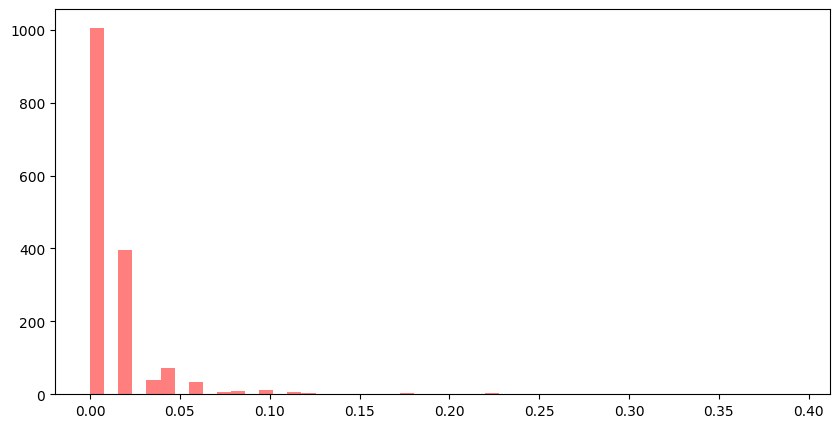

<Figure size 1000x500 with 0 Axes>

In [9]:
# Plot soft labels as a histogram
# Plot color coded histogram (group 0: red, group 1: blue)
plt.figure(figsize=(10, 5))
plt.hist(train_soft[np.where((train_labels == 0) & (train_attrs == 0))], bins=50, alpha=0.5, color='red', label='Group 0, Label 0')
# plt.hist(train_soft[np.where((train_labels == 1) & (train_attrs == 0))[0]][1], bins=50, alpha=0.5, color='orange', label='Group 0, Label 1')
# plt.hist(train_soft[np.where((train_labels == 0) & (train_attrs == 1))[0]][1], bins=50, alpha=0.5, color='blue', label='Group 1, Label 0')
# plt.hist(train_soft[np.where((train_labels == 1) & (train_attrs == 1))[0]][1], bins=50, alpha=0.5, color='cyan', label='Group 1, Label 1')


plt.figure(figsize=(10, 5))
#plt.hist(train_c[np.where((train_y == 0) & (train_a == 0))[0]], bins=50, alpha=0.5, color='red', label='Group 0, Label 0', density=True)
#plt.hist(train_c[np.where((train_y == 1) & (train_a == 0))[0]], bins=50, alpha=0.5, color='orange', label='Group 0, Label 1', density=True)
#plt.hist(train_c[np.where((train_y == 0) & (train_a == 1))[0]], bins=50, alpha=0.5, color='blue', label='Group 1, Label 0', density=True)
#plt.hist(train_c[np.where((train_y == 1) & (train_a == 1))[0]], bins=50, alpha=0.5, color='cyan', label='Group 1, Label 1', density=True)

In [10]:
# # plot the distribution
# def plot_distribution(samples, sensitive, labels, means, covars):
#     plt.figure(figsize=(10, 6))
#     color_00 = 'blue'
#     color_01 = 'orange'
#     color_10 = 'green'
#     color_11 = 'red'

#     indices_00 = np.where((labels == 0) & (sensitive == 0))[0]
#     indices_01 = np.where((labels == 0) & (sensitive == 1))[0]
#     indices_10 = np.where((labels == 1) & (sensitive == 0))[0]
#     indices_11 = np.where((labels == 1) & (sensitive == 1))[0]

#     plt.scatter(samples[indices_00, 0], samples[indices_00, 1], color=color_00, alpha=0.5, label='Label=0, Sensitive=0')
#     plt.scatter(samples[indices_01, 0], samples[indices_01, 1], color=color_01, alpha=0.5, label='Label=0, Sensitive=1')
#     plt.scatter(samples[indices_10, 0], samples[indices_10, 1], color=color_10, alpha=0.5, label='Label=1, Sensitive=0')
#     plt.scatter(samples[indices_11, 0], samples[indices_11, 1], color=color_11, alpha=0.5, label='Label=1, Sensitive=1')
#     plt.scatter(means['00'][0], means['00'][1], color=color_00, marker='x', s=100, label='Mean 00')
#     plt.scatter(means['01'][0], means['01'][1], color=color_01, marker='x', s=100, label='Mean 01')
#     plt.scatter(means['10'][0], means['10'][1], color=color_10, marker='x', s=100, label='Mean 10')
#     plt.scatter(means['11'][0], means['11'][1], color=color_11, marker='x', s=100, label='Mean 11')
#     plt.title('Distribution of Samples with Sensitive Attributes and Labels')
#     plt.xlabel('Feature 1')
#     plt.ylabel('Feature 2')
#     plt.legend()
#     plt.grid()
#     plt.show()
# plot_distribution(samples, sensitive, labels, means, covars)

### Baselines

In [11]:
import sys
import os
import pandas as pd
sys.path.append(os.path.join(os.getcwd(), 'FairPareto'))

from FairPareto.fairpareto.core import FairParetoClassifier

# Load your data (X should include the sensitive attribute column)
# Modified the class to work with custom soft labels
#feature_group = np.column_stack((samples, sensitive))
data_df = pd.DataFrame(all_embeddings)
data_df['sensitive'] = all_attrs
from sklearn.ensemble import RandomForestClassifier

clf = FairParetoClassifier(soft=[
    all_soft[np.where(all_attrs == 0)[0]],
    all_labels[np.where(all_attrs == 1)[0]]
], sensitive_column='sensitive', gamma_values= list(np.linspace(0, 0.5, 31)), verbose=True)
clf.fit(data_df, all_labels)

pareto_front = clf.get_pareto_front()
print(pareto_front)

/home/mohit/.conda/envs/llms/lib/python3.11/site-packages/xgboost/core.py:390: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(


FairPareto: Starting fit process...
  - Data shape: (10000, 513)
  - Strategy: histogram, n_bins: 10, k: 2
  - Preparing dataset...
  - Group 0 size: 4000, Group 1 size: 6000
  - Using provided calibrated classifier...
  - Computing Pareto front...
    - Applying histogram binning...
    - Optimization parameters: n=10, m=10, alpha=0.600
    - Running optimization for 31 gamma values...


/home/mohit/.conda/envs/llms/lib/python3.11/site-packages/cvxpy/atoms/affine/vec.py:40: FutureWarning: 
    You didn't specify the order of the vec expression. The default order
    used in CVXPY is Fortran ('F') order. This default will change to match NumPy's
    default order ('C') in a future version of CVXPY.
    To suppress this warning, please specify the order explicitly.
    
  warnings.warn(vec_order_warning, FutureWarning)
/home/mohit/.conda/envs/llms/lib/python3.11/site-packages/cvxpy/atoms/affine/reshape.py:68: FutureWarning: 
    You didn't specify the order of the reshape expression. The default order
    used in CVXPY is Fortran ('F') order. This default will change to match NumPy's
    default order ('C') in a future version of CVXPY.
    To suppress this warning, please specify the order explicitly.
    
  warnings.warn(reshape_order_warning, FutureWarning)


  - Pareto front computed with 31 points
FairPareto: Fit complete!
{np.float64(0.0): np.float64(0.10968999056738549), np.float64(0.016666666666666666): np.float64(0.10368999088270014), np.float64(0.03333333333333333): np.float64(0.09768999067691306), np.float64(0.05): np.float64(0.09168999122480356), np.float64(0.06666666666666667): np.float64(0.0870299905773878), np.float64(0.08333333333333333): np.float64(0.28346999990486765), np.float64(0.1): np.float64(0.07440999060477498), np.float64(0.11666666666666667): np.float64(0.0676899908805705), np.float64(0.13333333333333333): np.float64(0.06306999007102908), np.float64(0.15): np.float64(0.05568999069936427), np.float64(0.16666666666666666): np.float64(0.050829990647881004), np.float64(0.18333333333333332): np.float64(0.050809990142269966), np.float64(0.2): np.float64(0.050809990548666056), np.float64(0.21666666666666667): np.float64(0.05080999065187033), np.float64(0.23333333333333334): np.float64(0.05080999065293235), np.float64(0.25): 

In [18]:
# # Imports
# import numpy as np
# import torch
# import torch.nn as nn


# class FERMI(torch.nn.Module):

#     def __init__(self, X_train, X_test, Y_train, Y_test, S_train, S_test, batch_size=64, epochs=2000, lam=10):

#         super(FERMI, self).__init__()

#         self.X_train = X_train
#         self.Y_train = Y_train
#         self.X_test = X_test
#         self.Y_test = Y_test
#         self.S_train = S_train
#         self.S_test = S_test

#         self.batch_size = batch_size
#         self.epochs = epochs

#         self.n = X_train.shape[0]
#         self.d = X_train.shape[1]
#         self.m = Y_train.shape[1]
#         if self.m == 1:
#             self.m = 2

#         self.k = S_train.shape[1]

#         self.W = nn.Parameter(torch.zeros(self.k, self.m))  # k: Support of sensitive attributes, m: number of labels
#         self.theta = nn.Parameter(torch.zeros(self.d, 1))

#         sums = self.S_train.sum(axis=0) / self.n
#         print(sums)

#         print(sums.shape)

#         final_entries = []
#         for item in sums:
#             final_entries.append(1.0 / np.sqrt(item))

#         self.P_s = np.diag(sums)

#         self.P_s_sqrt_inv = torch.from_numpy(np.diag(final_entries)).double()
#         print(self.P_s_sqrt_inv)
#         self.lam = lam

#     def forward(self, X):
#         outputs = torch.mm(X.double(), self.theta.double())
#         logits = torch.sigmoid(outputs)
#         return logits

#     def fairness_regularizer(self, X, S):

#         current_batch_size = X.shape[0]
#         summation = 0

#         Y_hat = torch.sigmoid(torch.matmul(X, self.theta.double()))

#         for i in range(current_batch_size):
#             Y_hat_i = torch.zeros(self.m, self.m).double()
#             Y_hat_i[0][0] = 1.0 - Y_hat[i]
#             Y_hat_i[1][1] = Y_hat[i]

#             W_gram = torch.matmul(torch.t(self.W.double()), self.W.double())  # W^T W
#             summation -= torch.trace(torch.matmul(Y_hat_i, W_gram))

#             P_ys = torch.zeros(self.m, self.k).double()
#             P_ys[0][0] = S[i][0] * (1.0 - Y_hat[i])
#             P_ys[0][1] = S[i][1] * (1.0 - Y_hat[i])
#             P_ys[1][0] = S[i][0] * (Y_hat[i])
#             P_ys[1][1] = S[i][1] * (Y_hat[i])
#             prob_matrix_mul = torch.matmul(P_ys, self.P_s_sqrt_inv)
#             summation += 2 * torch.trace(torch.matmul(prob_matrix_mul, self.W.double())) - 1
#             #summation += 2 * torch.trace(torch.matmul(prob_matrix_mul, torch.t(self.W.double())))

#         return self.lam * summation


# ###
# def FERMI_Logistic_Regression(fermi, batch_size=64, epochs=1000, initial_epochs=300,
#                               initial_learning_rate=1, learning_rate_min=0.01, learning_rate_max=0.01, test_mode='on', test_report_at_every_x_epoch=10):

#     X = fermi.X_train
#     S_Matrix = fermi.S_train
#     Y = fermi.Y_train
#     XTest = fermi.X_test
#     STest = fermi.S_test
#     YTest = fermi.Y_test

#     criterion = torch.nn.BCELoss()
#     minimizer = torch.optim.SGD([fermi.theta, fermi.W], lr=initial_learning_rate)

#     for ep in range(epochs + initial_epochs):
#         if test_mode == 'on' and ep % test_report_at_every_x_epoch == test_report_at_every_x_epoch - 1:
#             print("Epoch Number: ", ep + 1)
#             # Test:
#             pre_logits = np.dot(XTest, fermi.theta.detach().numpy())
#             output_logits = 1 / (1 + np.exp(-pre_logits))
#             final_preds = output_logits > 0.5
#             test = YTest == 1
#             acc = final_preds == test
#             true_preds = acc.sum(axis=0)
#             print("Accuracy: ", true_preds[0] / output_logits.shape[0] * 100, "%")

#             final_preds = np.array(final_preds)
#             intersections = np.dot(final_preds.T, STest)
#             numbers = STest.sum(axis=0)

#             group1 = intersections[0][0] / numbers[0]
#             group2 = intersections[0][1] / numbers[1]
#             print("DP Violation: ", np.abs(group1 - group2))

#         number_of_iterations = X.shape[0] // batch_size
#         for i in range(number_of_iterations):

#             start = i * batch_size
#             end = (i + 1) * batch_size

#             current_batch_X = X[start:end]
#             current_batch_Y = Y[start:end]
#             current_batch_S = S_Matrix[start:end]

#             XTorch = torch.from_numpy(current_batch_X).double()
#             logits = fermi(XTorch)
#             YTorch = torch.from_numpy(current_batch_Y).double()
#             STorch = torch.from_numpy(current_batch_S).double()

#             # # Ensure Y is between 0 and 1 (convert if necessary)
#             # if YTorch.max() > 1.0 or YTorch.min() < 0.0:
#             #     YTorch = (YTorch - YTorch.min()) / (YTorch.max() - YTorch.min())
            
#             # logits = fermi.forward(XTorch)
            
#             # # Clamp logits to ensure they're in valid range
#             # logits = torch.clamp(logits, min=1e-7, max=1-1e-7)

#             if ep < initial_epochs:
#                 loss_min = criterion(logits, YTorch)
#             else:
#                 loss_min = criterion(logits, YTorch) + fermi.fairness_regularizer(XTorch, STorch)
#             # loss_min = criterion(logits, YTorch)

#             minimizer.zero_grad()
#             loss_min.backward()

#             if ep >= initial_epochs:
#                 fermi.theta.grad.data.mul_(learning_rate_min / initial_learning_rate)
#                 fermi.W.grad.data.mul_(-learning_rate_max / initial_learning_rate)

#             minimizer.step()
#     return fermi.theta, fermi.W

# from tqdm import tqdm

# all_weights = {}

# for lam in np.arange(10, 1000, 10):
#     fermi_instance = FERMI(train_embeddings, test_embeddings, train_soft.reshape(-1, 1), test_soft.reshape(-1, 1),
#                         S_train=np.eye(2)[train_attrs], S_test=np.eye(2)[test_attrs], batch_size=64, epochs=2000, lam=lam)
#     all_weights[lam] = FERMI_Logistic_Regression(fermi_instance)

In [12]:
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, TruePositiveRateParity
from sklearn.linear_model import LogisticRegression
from tqdm import tqdm
# Train Exp-grad
# Repeat for DP
eps_cls = {}
# for eps in tqdm([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]):
#     #constraint = DemographicParity()
#     constraint = TruePositiveRateParity()
#     mitigator = ExponentiatedGradient(LogisticRegression(), constraint, eps=eps)
#     mitigator.fit(samples, labels, sensitive_features=sensitive)
#     eps_cls[eps] = mitigator
for eps in tqdm([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3]):
    constraint = DemographicParity()
    #constraint = TruePositiveRateParity()
    mitigator = ExponentiatedGradient(LogisticRegression(), constraint, eps=eps)
    mitigator.fit(train_embeddings, train_labels, sensitive_features=train_attrs)
    eps_cls[eps] = mitigator

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:25<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
from sklearn.metrics import accuracy_score
from fairlearn.metrics import demographic_parity_difference, true_positive_rate_difference, true_positive_rate
unfs = []
errs = []
eps = []

def signed_dp(y_true, y_pred, sensitive_features):
    group_0 = np.where(sensitive_features == 0)[0]
    group_1 = np.where(sensitive_features == 1)[0]
    pr_1_a0 = np.mean(y_pred[group_0])
    pr_1_a1 = np.mean(y_pred[group_1])
    return pr_1_a1 - pr_1_a0


unfair_model = LogisticRegression().fit(np.concatenate((train_embeddings, train_attrs.reshape(-1,1)), axis=1), train_labels)
preds = unfair_model.predict(np.concatenate((test_embeddings, test_attrs.reshape(-1,1)), axis=1))
unfair_err = 1 - accuracy_score(test_labels, preds)
unfair_unf = signed_dp(test_labels, preds, sensitive_features=test_attrs)

#unfair_unf = true_positive_rate(test_y[np.where(test_a == 1)[0]], preds[np.where(test_a == 1)[0]]) - true_positive_rate(test_y[np.where(test_a == 0)[0]], preds[np.where(test_a == 0)[0]])
#unfair_unf = true_positive_rate(est_labels[np.where(est_sensitive == 1)[0]], preds[np.where(est_sensitive == 1)[0]]) - true_positive_rate(est_labels[np.where(est_sensitive == 0)[0]], preds[np.where(est_sensitive == 0)[0]])

# for e in eps_cls.keys():
#     mitigated_test_preds = eps_cls[e].predict(test_x)
#     #unfs.append(demographic_parity_difference(est_labels, mitigated_test_preds, sensitive_features=est_sensitive))
#     #unfs.append(signed_dp(est_labels, mitigated_test_preds, est_sensitive))
#     unfs.append(true_positive_rate(test_y[np.where(test_a == 1)[0]], mitigated_test_preds[np.where(test_a == 1)[0]]) - true_positive_rate(test_y[np.where(test_a == 0)[0]], mitigated_test_preds[np.where(test_a == 0)[0]]))
#     errs.append(1 - accuracy_score(test_y, mitigated_test_preds))
#     eps.append(e)

for e in eps_cls.keys():
    mitigated_test_preds = eps_cls[e].predict(test_embeddings)
    #unfs.append(demographic_parity_difference(est_labels, mitigated_test_preds, sensitive_features=est_sensitive))
    unfs.append(signed_dp(test_labels, mitigated_test_preds, test_attrs))
    #unfs.append(true_positive_rate(est_labels[np.where(est_sensitive == 1)[0]], mitigated_test_preds[np.where(est_sensitive == 1)[0]]) - true_positive_rate(est_labels[np.where(est_sensitive == 0)[0]], mitigated_test_preds[np.where(est_sensitive == 0)[0]]))
    errs.append(1 - accuracy_score(test_labels, mitigated_test_preds))
    eps.append(e)

# Add the unfair model point
unfs.append(unfair_unf)
errs.append(unfair_err)
eps.append(0)

# Sort by errors
temp = sorted(zip(unfs, errs, eps), key=lambda x: x[1])
unfs, errs, eps = zip(*temp)

In [ ]:
### Fairret
from baselines import train_fairret
strength_values = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.5]
points = {}
for val in tqdm(strength_values):
    points[val] = train_fairret(train_embeddings, train_labels, train_attrs, test_embeddings, test_labels, test_attrs, fairness_strength=val, metric='dp')

100%|██████████| 8/8 [01:21<00:00, 10.14s/it]


### Algorithm

In [16]:
from utils import soft_estimator, test_monotonicity

estimated_priors = soft_estimator(train_soft, train_attrs)
D = {
    'C': np.asarray(train_soft),
    'A': train_attrs
}

priors = soft_estimator(all_soft, all_attrs)
D_est = {
    'C': np.asarray(test_soft),
    'A': test_attrs
}

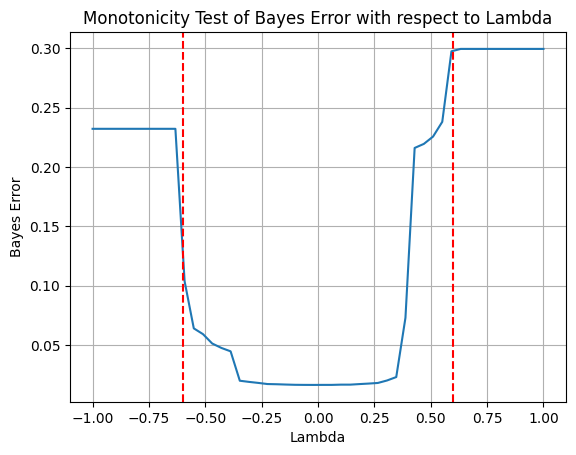

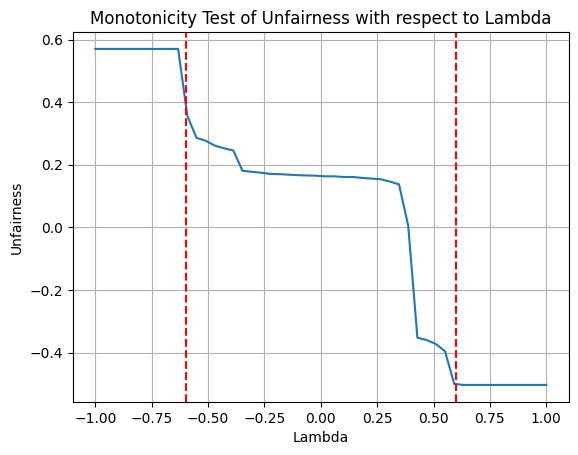

In [17]:
test_monotonicity(estimated_priors, D_est, 'dp')

In [18]:
from utils import return_tradeoff

true_tradeoff, true_bayes, true_unf = return_tradeoff(D_est, priors, constraint='dp', delta=0.001, eps=0.0001)

0.01606961488723746 0.16500000000000004 0.6
lambda: 0.3, Alpha_0: 0.12500000000000006, Alpha_1: 0.75, Error: 0.019815826416015536, Unfairness: 0.14625, Lam Min: 0, Lam Max: 0.6
lambda: 0.44999999999999996, Alpha_0: 0, Alpha_1: 0.875, Error: 0.21622612476348868, Unfairness: -0.3533333333333334, Lam Min: 0.3, Lam Max: 0.6
lambda: 0.375, Alpha_0: 0.03125, Alpha_1: 0.8125, Error: 0.038545095920562655, Unfairness: 0.09416666666666662, Lam Min: 0.3, Lam Max: 0.44999999999999996
lambda: 0.4125, Alpha_0: 0, Alpha_1: 0.84375, Error: 0.2151681125164031, Unfairness: -0.35083333333333333, Lam Min: 0.375, Lam Max: 0.44999999999999996
lambda: 0.39375, Alpha_0: 0.007812500000000056, Alpha_1: 0.828125, Error: 0.07298185825347892, Unfairness: 0.004583333333333384, Lam Min: 0.375, Lam Max: 0.4125
lambda: 0.40312499999999996, Alpha_0: 0, Alpha_1: 0.8359375, Error: 0.21448182463645926, Unfairness: -0.3491666666666666, Lam Min: 0.39375, Lam Max: 0.4125
lambda: 0.3984375, Alpha_0: 0.001953125, Alpha_1: 0.83

In [19]:
est_tradeoff, est_bayes, est_unf = return_tradeoff(D_est, estimated_priors, constraint='dp', delta=0.001, eps=0.0001)

0.016238713264465354 0.16500000000000004 0.6
lambda: 0.3, Alpha_0: 0.12500000000000006, Alpha_1: 0.75, Error: 0.01998492479324343, Unfairness: 0.14625, Lam Min: 0, Lam Max: 0.6
lambda: 0.44999999999999996, Alpha_0: 0, Alpha_1: 0.875, Error: 0.21639522314071657, Unfairness: -0.3533333333333334, Lam Min: 0.3, Lam Max: 0.6
lambda: 0.375, Alpha_0: 0.03125, Alpha_1: 0.8125, Error: 0.03871419429779055, Unfairness: 0.09416666666666662, Lam Min: 0.3, Lam Max: 0.44999999999999996
lambda: 0.4125, Alpha_0: 0, Alpha_1: 0.84375, Error: 0.215337210893631, Unfairness: -0.35083333333333333, Lam Min: 0.375, Lam Max: 0.44999999999999996
lambda: 0.39375, Alpha_0: 0.007812500000000056, Alpha_1: 0.828125, Error: 0.07315095663070681, Unfairness: 0.004583333333333384, Lam Min: 0.375, Lam Max: 0.4125
lambda: 0.40312499999999996, Alpha_0: 0, Alpha_1: 0.8359375, Error: 0.21465092301368716, Unfairness: -0.3491666666666666, Lam Min: 0.39375, Lam Max: 0.4125
lambda: 0.3984375, Alpha_0: 0.001953125, Alpha_1: 0.8320

In [20]:
def plot_tradeoff(tradeoff, tradeoff_est, true_bayes, true_unf, predicted_points=None):
    x = []
    y = []
    colors = []
    for key in tradeoff:
        #if key != -1:
        x.append(tradeoff[key][0])
        y.append(tradeoff[key][1])
        colors.append(tradeoff[key][2])
    x = np.array(x)
    y = np.array(y)
    plt.scatter(x, y, c=colors, cmap='viridis', label='True Trade-off')
    # x_y_spline = interp1d(x, y, kind='cubic')
    # X_ = np.linspace(x.min(), x.max(), 500)
    # Y_ = x_y_spline(X_)
    # plt.plot(X_, Y_, color='blue', linestyle='--', label='True Trade-off (spline)')
    # Draw a vertical line at the bayes optimal point
    plt.axvline(x=true_bayes, color='black', linestyle='--')
    plt.axhline(y=true_unf, color='black', linestyle='--')
    plt.colorbar(label='Lambda')
    x_est = []
    y_est = []
    colors_est = []
    for key in tradeoff_est:
        #if key != -1:
        x_est.append(tradeoff_est[key][0])
        y_est.append(tradeoff_est[key][1])
        colors_est.append(tradeoff_est[key][2])
    x_est = np.array(x_est)
    y_est = np.array(y_est)
    plt.scatter(x_est, y_est, c=colors_est, cmap='plasma', marker='x', label='Estimated Trade-off')
    # remove duplicates from x_est, y_est, colors_est
    # unique_indices = np.unique(x_est, return_index=True)[1]
    # u_x_est = x_est[unique_indices]
    # u_y_est = y_est[unique_indices]
    # u_colors_est = np.array(colors_est)[unique_indices]
    # x_y_spline_est = interp1d(u_x_est, u_y_est, kind='cubic')
    # X_est_ = np.linspace(x_est.min(), x_est.max(), 500)
    # Y_est_ = x_y_spline_est(X_est_)
    # plt.plot(X_est_, Y_est_, color='orange', linestyle='--', label='Estimated Trade-off (spline)')
    plt.colorbar(label='Lambda (Estimated)')
    if predicted_points is not None:
        if 'exp_grad' in predicted_points:
            unfs, errs, eps = predicted_points['exp_grad']
            unfs = np.array(unfs)
            errs = np.array(errs)
            plt.scatter(errs, unfs, c='green', marker='^', label='Fairlearn Exp-Grad')
        if 'pareto' in predicted_points:
            unfs_p, errs_p = list(predicted_points['pareto'].keys()), list(predicted_points['pareto'].values())
            unfs_p = np.array(unfs_p)
            errs_p = np.array(errs_p)
            plt.scatter(errs_p, unfs_p, c='red', marker='s', label='MIFPO')
        if 'fairret' in predicted_points:
            points_fairret = predicted_points['fairret']
            eps_fairret = []
            unfs_fairret = []
            errs_fairret = []
            for key in points_fairret:
                errs_fairret.append(points_fairret[key][0])
                unfs_fairret.append(points_fairret[key][1])
                eps_fairret.append(key)
            unfs_fairret = np.array(unfs_fairret)
            errs_fairret = np.array(errs_fairret)
            plt.scatter(errs_fairret, unfs_fairret, c='blue', marker='*', label='FairRet')
        # Remove duplicates
        # unique_indices_exp = np.unique(errs, return_index=True)[1]
        # u_errs = errs[unique_indices_exp]
        # u_unfs = unfs[unique_indices_exp]
        # x_y_spline_exp = interp1d(u_errs, u_unfs, kind='cubic')
        # X_exp_ = np.linspace(errs.min(), errs.max(), 500)
        # Y_exp_ = x_y_spline_exp(X_exp_)
        # plt.plot(X_exp_, Y_exp_, color='green', linestyle='--', label='Fairlearn Exp-Grad (spline)')
        # unfs_fairret, errs_fairret, eps_fairret = predicted_points['fairret']
        # unfs_fairret = np.array(unfs_fairret)
        # errs_fairret = np.array(errs_fairret)
        # Remove duplicates
        # unique_indices_fairret = np.unique(errs_fairret, return_index=True)[1]
        # u_errs_fairret = errs_fairret[unique_indices_fairret]
        # u_unfs_fairret = unfs_fairret[unique_indices_fairret]
        # x_y_spline_fairret = interp1d(u_errs_fairret, u_unfs_fairret, kind='cubic')
        # X_fairret_ = np.linspace(errs_fairret.min(), errs_fairret.max(), 500)
        # Y_fairret_ = x_y_spline_fairret(X_fairret_)
        # plt.plot(X_fairret_, Y_fairret_, color='red', linestyle='--', label='FairRet (spline)')
        #plt.scatter(errs_fairret, unfs_fairret, c='red', marker='s', label='FairRet')
    plt.xlabel('Bayes Error')
    plt.ylabel('Unfairness')
    #plt.ylim(-0.05, 0.15)
    #plt.xlim(0.075, 0.15)
    plt.title('Trade-off Curve')
    plt.legend()

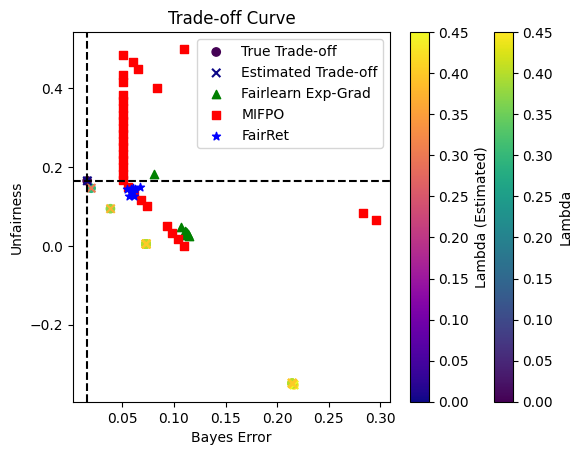

In [21]:
#from utils import plot_tradeoff
plot_tradeoff(true_tradeoff, est_tradeoff, true_bayes, true_unf, {'exp_grad':(unfs, errs, eps), 'pareto':pareto_front, 'fairret':points})